# Анализ временного ряда продаж

Исследуем продажи **LUNCH BAG BLACK SKULL**, сумки для обеда с черепом, код `20727`. Товар отличается от разобранного на занятии `85123A`.

Задача: построить дневной, недельный и месячный ряды, проверить качество данных, тренд, сезонность и стационарность. Источник — [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online-retail), Chen, D. (2015), [DOI 10.24432/C5BW33](https://doi.org/10.24432/C5BW33), CC BY 4.0.

Запускайте ячейки по порядку из корня репозитория. При первом запуске данные скачиваются в `data/raw/`, затем используется локальная копия.

In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.signal import detrend
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss

data_path = Path('data/raw/Online Retail.xlsx')
if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    with urlopen('https://archive.ics.uci.edu/static/public/352/online+retail.zip', timeout=120) as response:
        with ZipFile(BytesIO(response.read())) as archive:
            data_path.write_bytes(archive.read('Online Retail.xlsx'))

df = pd.read_excel(data_path, engine='openpyxl', parse_dates=['InvoiceDate'],
                   dtype={'InvoiceNo': 'string', 'StockCode': 'string', 'CustomerID': 'string'})
display(df.head())
df.info()
print(f'Период: {df.InvoiceDate.min()} — {df.InvoiceDate.max()}')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), object(1), str(1), string(3)
memory usage: 33.1+ MB
Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


## 1. Подготовка данных и методы анализа

`StockCode` определяет товар, `InvoiceDate` — дату, `Quantity` — количество единиц, `UnitPrice` — цену в GBP. `InvoiceNo`, начинающийся с `C`, означает отмену. `Description` содержит название, `CustomerID` — покупателя, `Country` — его страну.

Показатель ряда — **количество положительных продаж**: оставляем `Quantity > 0`, `UnitPrice > 0` и документы без префикса `C`. Возвраты не вычитаем, поэтому это не продажи за вычетом возвратов. Класс хранит исходные операции товара и отдельно подготовленные продажи; основные расчёты выполняем его методами.

In [2]:
class SalesAnalysis:
    """Анализ положительных продаж одного товара."""

    def __init__(self, raw, product_code):
        self.raw = raw
        self.product = raw.loc[raw.StockCode.eq(product_code)].copy()
        cancelled = self.product.InvoiceNo.str.upper().str.startswith('C', na=False)
        self.sales = self.product.loc[
            self.product.Quantity.gt(0) & self.product.UnitPrice.gt(0) & ~cancelled
        ].copy()
        self.start = raw.InvoiceDate.min().normalize()
        self.end = raw.InvoiceDate.max().normalize()

    def aggregate(self):
        daily = (self.sales.set_index('InvoiceDate').resample('D')
                 .agg(units=('Quantity', 'sum'), rows=('Quantity', 'size'))
                 .reindex(pd.date_range(self.start, self.end, freq='D'), fill_value=0))
        daily.index.name = 'date'
        daily['full_period'] = (daily.index > self.start) & (daily.index < self.end)
        self.tables = {'daily': daily}
        for name, frequency, period in [('weekly', 'W-SUN', 'W-SUN'), ('monthly', 'MS', 'M')]:
            table = daily[['units', 'rows']].resample(frequency).sum()
            periods = table.index.to_period(period)
            table['full_period'] = ((periods.start_time > self.start)
                                    & (periods.end_time.normalize() < self.end))
            self.tables[name] = table
        self.series = daily.loc[daily.full_period, 'units'].astype(float)
        return pd.DataFrame({name: {
            'Периодов': len(table), 'Полных': int(table.full_period.sum()),
            'Без продаж': int(table.rows.eq(0).sum()), 'Продано единиц': table.units.sum()
        } for name, table in self.tables.items()}).T

    def quality(self):
        missing = self.product.isna().sum().to_frame('Пропусков')
        for column in self.product.columns:
            dates = self.product.loc[self.product[column].isna(), 'InvoiceDate']
            missing.loc[column, 'Первая дата пропуска'] = dates.min()
            missing.loc[column, 'Последняя дата пропуска'] = dates.max()
        self.calendar = pd.DataFrame(index=self.tables['daily'].index)
        self.calendar['any_operations'] = self.calendar.index.isin(self.raw.InvoiceDate.dt.normalize())
        self.calendar['product_sales'] = self.tables['daily'].rows.gt(0)
        checks = pd.Series({
            'Дубликатов строк товара': int(self.product.duplicated().sum()),
            'NaN в дневном ряду': int(self.tables['daily'].units.isna().sum()),
            'Дней без операций во всём датасете': int((~self.calendar.any_operations).sum()),
            'Дней с операциями, но без продаж товара': int((self.calendar.any_operations & ~self.calendar.product_sales).sum()),
        })
        return missing, checks

    def outliers(self):
        result = {}
        for name in ['daily', 'weekly']:
            table = self.tables[name]
            q1, q3 = table.loc[table.full_period, 'units'].quantile([0.25, 0.75])
            limit = q3 + 1.5 * (q3 - q1)
            result[name] = (limit, table.loc[table.units.gt(limit)])
        return result

    def statistics(self):
        result = {}
        for name, table in self.tables.items():
            values = table.loc[table.full_period, 'units']
            stats = values.agg(['count', 'mean', 'median', 'std', 'min', 'max'])
            stats['CV'] = values.std() / values.mean()
            stats['zero_pct'] = values.eq(0).mean() * 100
            result[name] = stats
        return pd.DataFrame(result).T

    def decompose(self):
        result = STL(self.series, period=7, seasonal=13, trend=29, robust=True).fit()
        return pd.DataFrame({'Продажи': self.series, 'Тренд': result.trend,
                             'Недельная компонента': result.seasonal, 'Остаток': result.resid})

    def stationarity(self):
        self.diff7 = self.series.diff(7).iloc[7:]
        rows = []
        for name, values in [('Исходный', self.series), ('Разность 7', self.diff7)]:
            a_stat, a_p, a_lags, _, _, _ = adfuller(values, regression='c', autolag='AIC', result_object=False)
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', InterpolationWarning)
                k_stat, k_p, k_lags, critical = kpss(values, regression='c', nlags=14, result_object=False)
            k_label = ('< 0.01' if k_stat > critical['1%'] else
                       '> 0.10' if k_stat < critical['10%'] else f'{k_p:.4f}')
            rows.extend([
                [name, 'ADF', len(values), a_stat, f'{a_p:.4g}', a_lags],
                [name, 'KPSS', len(values), k_stat, k_label, k_lags],
            ])
        return pd.DataFrame(rows, columns=['Ряд', 'Тест', 'N', 'Статистика', 'p-value', 'Лаги'])


def format_dates(ax, weeks=None):
    """Календарные подписи, одинаковые на всех временных графиках."""
    if weeks is None:
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
        ax.tick_params(axis='x', labelrotation=45, labelsize=9)
    else:
        ax.set_xticks(weeks)
        ax.set_xticklabels([f'{day:%d.%m.%Y} / нед. {day.isocalendar().week:02d}' for day in weeks],
                           rotation=90, fontsize=8)
    ax.set_xlabel('Дата' if weeks is None else 'Воскресенье / номер недели ISO')
    ax.grid(alpha=0.2)
    ax.margins(x=0.015)

In [3]:
analysis = SalesAnalysis(df, '20727')
display(pd.Series({
    'Исходных строк товара': len(analysis.product),
    'Quantity <= 0': int(analysis.product.Quantity.le(0).sum()),
    'UnitPrice <= 0': int(analysis.product.UnitPrice.le(0).sum()),
    'Отмен (C)': int(analysis.product.InvoiceNo.str.upper().str.startswith('C', na=False).sum()),
    'Строк после отбора': len(analysis.sales),
    'Всего исключено': len(analysis.product) - len(analysis.sales),
}).to_frame('Количество'))

,Количество
Исходных строк товара,1350
Quantity <= 0,22
UnitPrice <= 0,0
Отмен (C),22
Строк после отбора,1328
Всего исключено,22


## 2. Агрегация по дням, неделям и месяцам

Используем общий интервал дат датасета. День без подходящих транзакций получает ноль **зарегистрированных продаж**, предполагая полноту журнала. Это не восстановление потерянного наблюдения; ниже проверяем покрытие календаря.

Недели идут с понедельника по воскресенье, месяцы — календарные. `full_period=False` отмечает периоды, затронутые границами данных. Первый и последний дни также считаем потенциально неполными. Их сохраняем на графиках, но исключаем из описательных статистик.

,Периодов,Полных,Без продаж,Продано единиц
daily,374,372,82,12240
weekly,54,52,1,12240
monthly,13,11,0,12240


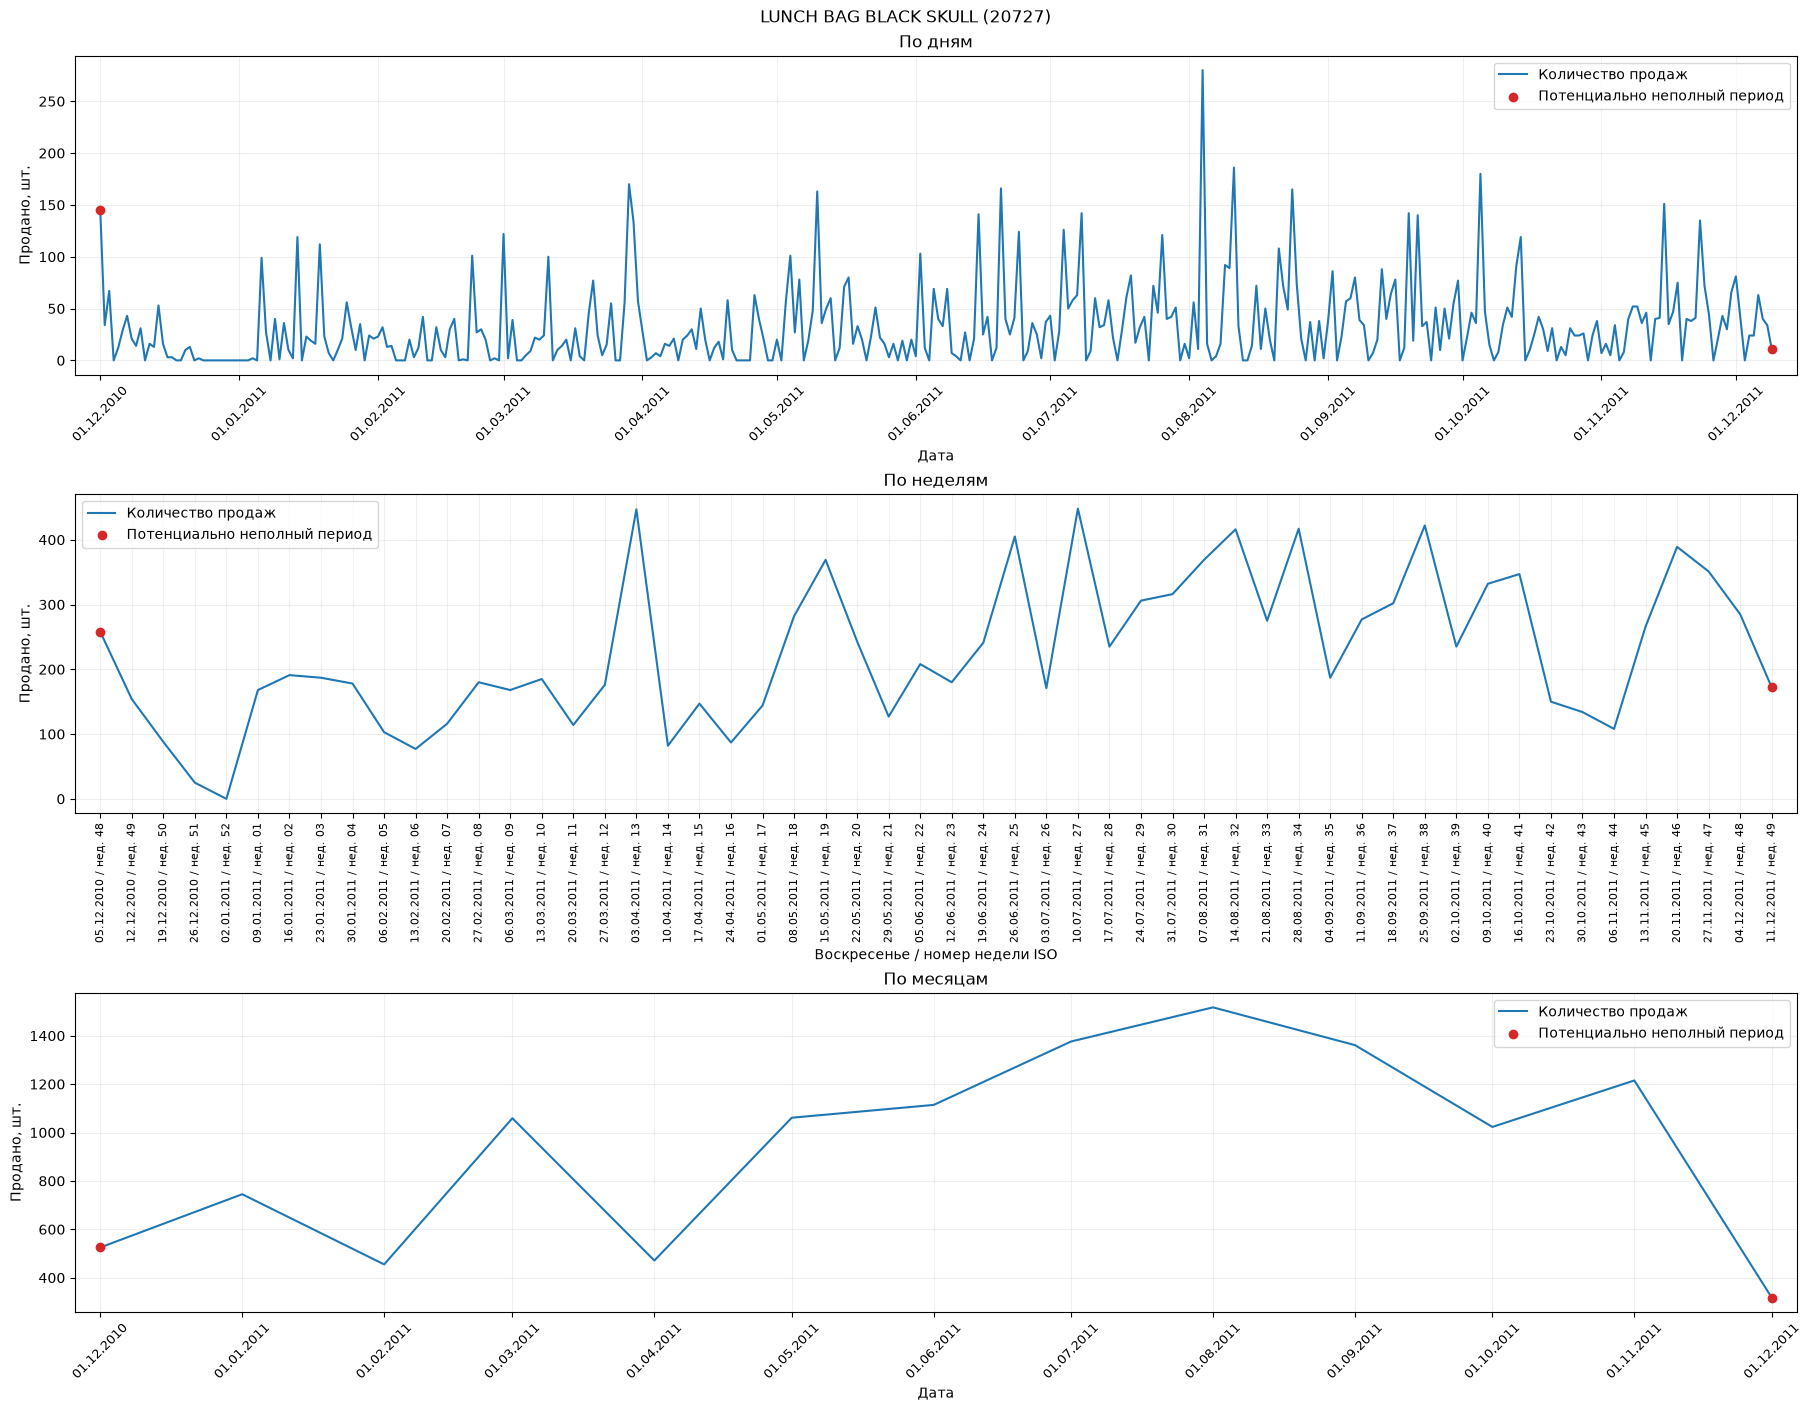

In [4]:
summary = analysis.aggregate()
display(summary)
assert summary['Продано единиц'].nunique() == 1

fig, axes = plt.subplots(3, 1, figsize=(18, 14), constrained_layout=True)
for ax, (name, table), title in zip(axes, analysis.tables.items(), ['По дням', 'По неделям', 'По месяцам']):
    ax.plot(table.index, table.units, label='Количество продаж')
    edges = table.loc[~table.full_period]
    ax.scatter(edges.index, edges.units, color='tab:red', label='Потенциально неполный период', zorder=3)
    ax.set(title=title, ylabel='Продано, шт.')
    format_dates(ax, table.index if name == 'weekly' else None)
    ax.legend()
fig.suptitle('LUNCH BAG BLACK SKULL (20727)')
plt.show()

## 3. Качество данных

Проверим пропуски полей и их расположение, дубликаты, дни без операций магазина и дни без продаж только выбранного товара. Это разные причины отсутствия значений в транзакционной таблице и нулей в агрегированном ряду.

In [5]:
missing, quality = analysis.quality()
display(missing)
display(quality.to_frame('Количество'))
no_operations = analysis.calendar.index[~analysis.calendar.any_operations]
print('Суббот без операций:', int((no_operations.day_of_week == 5).sum()))
print('Даты с операциями магазина, но без продаж товара:')
print(analysis.calendar.index[analysis.calendar.any_operations & ~analysis.calendar.product_sales].strftime('%d.%m.%Y').tolist())

,Пропусков,Первая дата пропуска,Последняя дата пропуска
InvoiceNo,0,NaT,NaT
StockCode,0,NaT,NaT
Description,0,NaT,NaT
Quantity,0,NaT,NaT
InvoiceDate,0,NaT,NaT
UnitPrice,0,NaT,NaT
CustomerID,224,2010-12-01 17:06:00,2011-12-09 10:23:00
Country,0,NaT,NaT


,Количество
Дубликатов строк товара,27
NaN в дневном ряду,0
Дней без операций во всём датасете,69
"Дней с операциями, но без продаж товара",13


Суббот без операций: 53
Даты с операциями магазина, но без продаж товара:
['19.12.2010', '22.12.2010', '05.01.2011', '06.02.2011', '07.02.2011', '13.02.2011', '21.02.2011', '28.02.2011', '04.03.2011', '16.03.2011', '27.03.2011', '13.06.2011', '14.08.2011']


Пропусков в полях для агрегации нет; 224 пропуска `CustomerID` не мешают анализу общего количества продаж. В дневном ряду NaN нет. Из 82 нулевых дней 69 не содержат операций вообще, включая все 53 субботы; в оставшиеся 13 дней другие товары продавались. По журналу нельзя установить, был ли магазин закрыт или были потеряны операции. Нули оставляем как отсутствие зарегистрированных продаж, без интерполяции.

27 полных дубликатов сохраняем: без идентификатора позиции документа нельзя уверенно отличить ошибку записи от одинаковых реальных позиций. Это ограничение точности итоговых сумм.

## 4. Потенциальные выбросы

Используем верхнюю границу `Q3 + 1.5 × IQR`, рассчитанную по полным дневным и недельным периодам. Это кандидаты для проверки, а не правило удаления: метод не учитывает сезонность. Нулевые продажи не считаем выбросами. Проверим крупнейший день по исходным позициям документов.

,"Граница IQR, шт.",Кандидатов
daily,103.375,23.0
weekly,551.875,0.0


,InvoiceDate,InvoiceNo,Quantity,UnitPrice
289663,2011-08-04 10:23:00,562276,10,1.65
289729,2011-08-04 10:38:00,562282,30,1.65
289750,2011-08-04 10:43:00,562283,10,1.65
289832,2011-08-04 11:44:00,562332,200,1.45
290109,2011-08-04 13:15:00,562353,20,1.65
291282,2011-08-04 18:44:00,562444,10,1.65


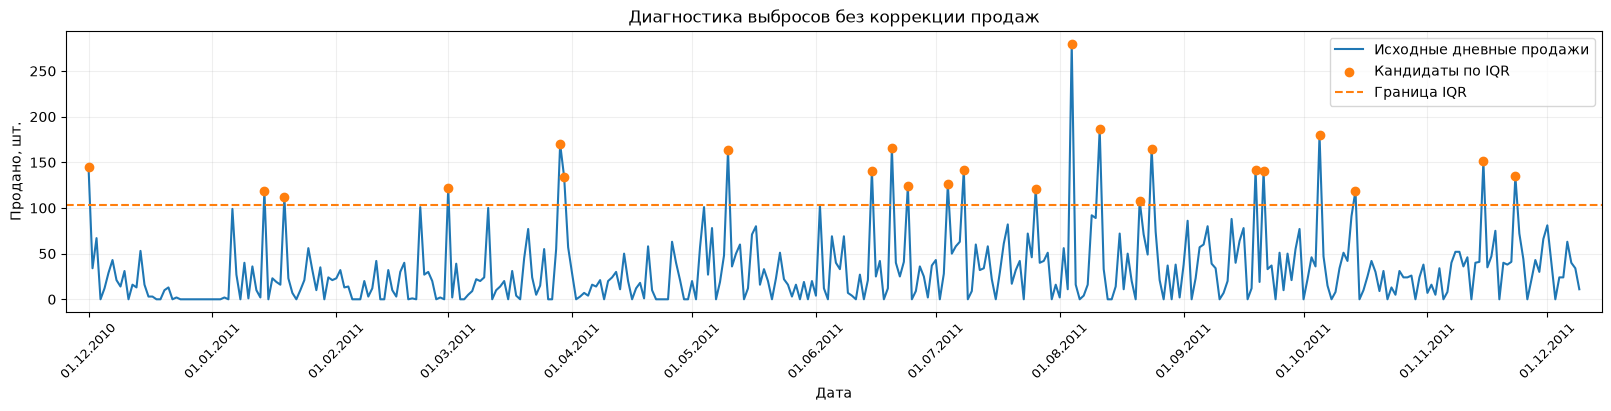

In [6]:
outliers = analysis.outliers()
display(pd.DataFrame({name: {'Граница IQR, шт.': limit, 'Кандидатов': len(points)}
                      for name, (limit, points) in outliers.items()}).T)
daily = analysis.tables['daily']
peak_day = daily.units.idxmax()
peak_rows = analysis.sales.loc[analysis.sales.InvoiceDate.dt.normalize().eq(peak_day)]
display(peak_rows[['InvoiceDate', 'InvoiceNo', 'Quantity', 'UnitPrice']])

fig, ax = plt.subplots(figsize=(16, 4), constrained_layout=True)
ax.plot(daily.index, daily.units, label='Исходные дневные продажи')
limit, points = outliers['daily']
ax.scatter(points.index, points.units, color='tab:orange', label='Кандидаты по IQR', zorder=3)
ax.axhline(limit, color='tab:orange', linestyle='--', label='Граница IQR')
ax.set(title='Диагностика выбросов без коррекции продаж', ylabel='Продано, шт.')
format_dates(ax)
ax.legend()
plt.show()

Дневная граница — 103,38 шт., отмечены 23 кандидата, включая один пограничный день. На недельной частоте превышений нет. Максимум **04.08.2011 — 280 сумок**: одна позиция на 200 единиц даёт 71,4% объёма дня. Это согласуется с крупной оптовой покупкой; ошибка не установлена. Сохраняем исходные продажи без коррекции пиков.

## 5. Описательный анализ

Рассчитаем статистики по полным периодам. Дополнительные характеристики — коэффициент вариации `CV = std / mean` и доля нулевых периодов `zero_pct`. Изменение уровня и разброса исследуем по скользящим среднему и стандартному отклонению с окном 28 дней — четыре недели. Первые 27 оценок не определены из-за недостатка полного окна.

,count,mean,median,std,min,max,CV,zero_pct
daily,372.0,32.48,21.5,38.58,0.0,280.0,1.19,22.04
weekly,52.0,227.12,189.0,115.30,0.0,448.0,0.51,1.92
monthly,11.0,1036.09,1061.0,351.21,455.0,1517.0,0.34,0.00


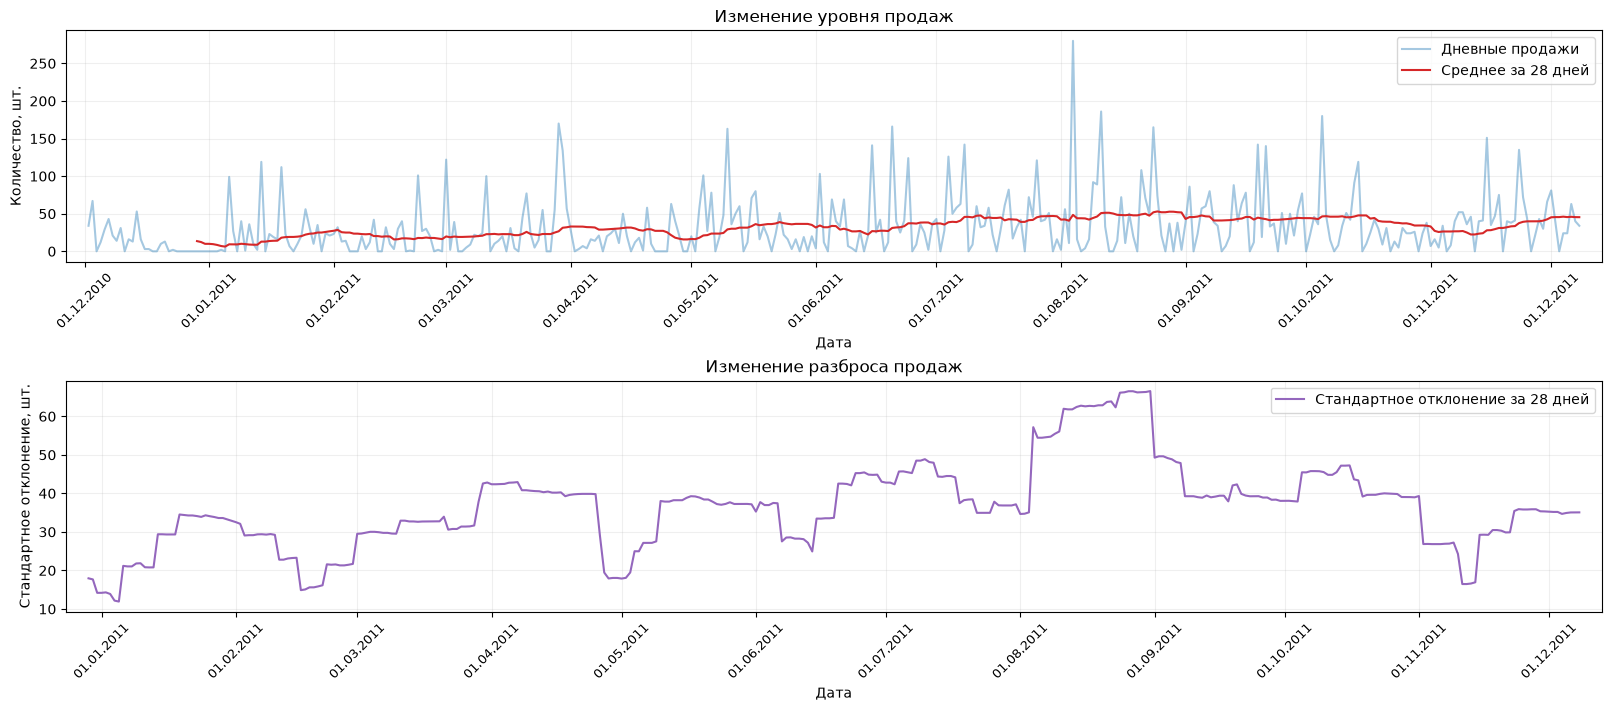

In [7]:
statistics = analysis.statistics()
display(statistics.round(2))
rolling = analysis.series.rolling(28, min_periods=28)
fig, axes = plt.subplots(2, 1, figsize=(16, 7), constrained_layout=True)
axes[0].plot(analysis.series.index, analysis.series, alpha=0.4, label='Дневные продажи')
axes[0].plot(analysis.series.index, rolling.mean(), color='tab:red', label='Среднее за 28 дней')
axes[0].set(title='Изменение уровня продаж', ylabel='Количество, шт.')
axes[1].plot(analysis.series.index, rolling.std(), color='tab:purple', label='Стандартное отклонение за 28 дней')
axes[1].set(title='Изменение разброса продаж', ylabel='Стандартное отклонение, шт.')
for ax in axes:
    format_dates(ax)
    ax.legend()
plt.show()

По 372 полным дням среднее равно **32,48**, медиана — **21,5**, стандартное отклонение — **38,58** сумки. Крупные покупки повышают среднее относительно медианы. Нулевые продажи наблюдаются в 22,04% полных дней. При недельной агрегации CV уменьшается с 1,19 до 0,51: колебания сглаживаются, но остаётся только 52 полных наблюдения. Месячных наблюдений всего 11.

Скользящие среднее и разброс меняются во времени: уровень ниже в начале периода, выше летом и осенью; разброс особенно велик в августе. Стационарность проверим статистическими тестами.

## 6. Недельная периодичность

Сопоставим средние продажи по дням недели и ACF после удаления линейного тренда. Недельные лаги означают 7, 14, 21 и 28 календарных дней; субботы из ряда не удаляем. Интервалы ACF поточечные, поэтому отдельное превышение границы само по себе не доказывает сезонность.

ACF без линейного тренда на лагах 7, 14, 21, 28: [0.184 0.227 0.042 0.194]


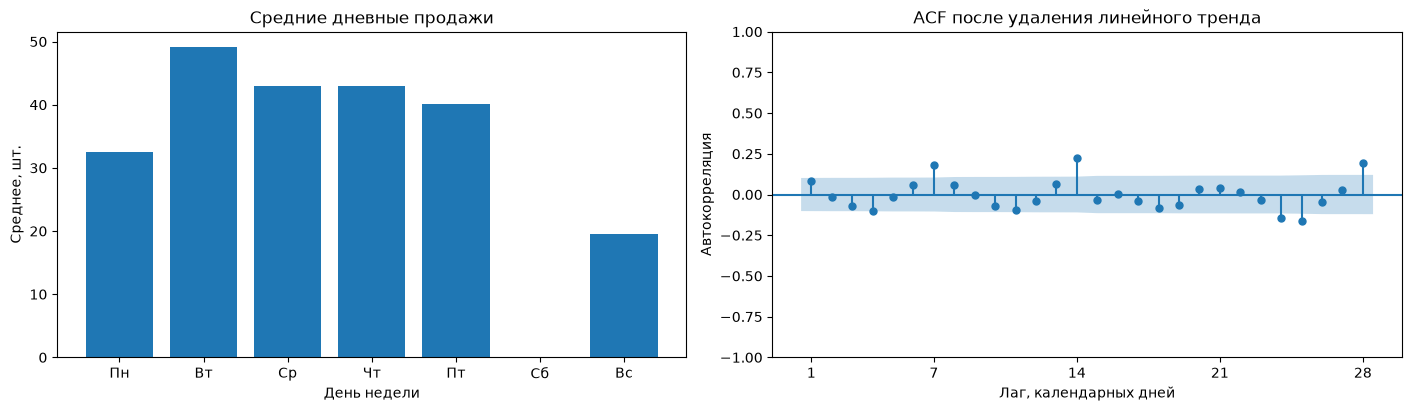

In [8]:
weekday_means = analysis.series.groupby(analysis.series.index.day_of_week).mean()
weekday_means.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
without_trend = detrend(analysis.series.to_numpy(), type='linear')
acf_values = acf(without_trend, nlags=28, result_object=False)
print('ACF без линейного тренда на лагах 7, 14, 21, 28:', acf_values[[7, 14, 21, 28]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
axes[0].bar(weekday_means.index, weekday_means)
axes[0].set(title='Средние дневные продажи', xlabel='День недели', ylabel='Среднее, шт.')
plot_acf(without_trend, lags=28, zero=False, ax=axes[1], title='ACF после удаления линейного тренда')
axes[1].set(xlabel='Лаг, календарных дней', ylabel='Автокорреляция', xticks=[1, 7, 14, 21, 28])
plt.show()

Средние продажи выше во вторник, ниже в воскресенье; субботы нулевые. После удаления линейного тренда ACF на лагах 7, 14 и 28 равна 0,184, 0,227 и 0,194; связь на лаге 21 слабее. Вместе с профилем недели это поддерживает недельную календарную периодичность. Она частично связана с отсутствием операций магазина по субботам; сезонность спроса отдельно не установлена.

## 7. Декомпозиция

Применим аддитивный STL с периодом 7: `продажи = тренд + недельная компонента + остаток`. Аддитивная модель допускает нули. Робастный режим уменьшает влияние крупных заказов на сглаживание, сохраняя их в остатке. Окна сглаживания: 13 циклов для сезонности и 29 дней для тренда.

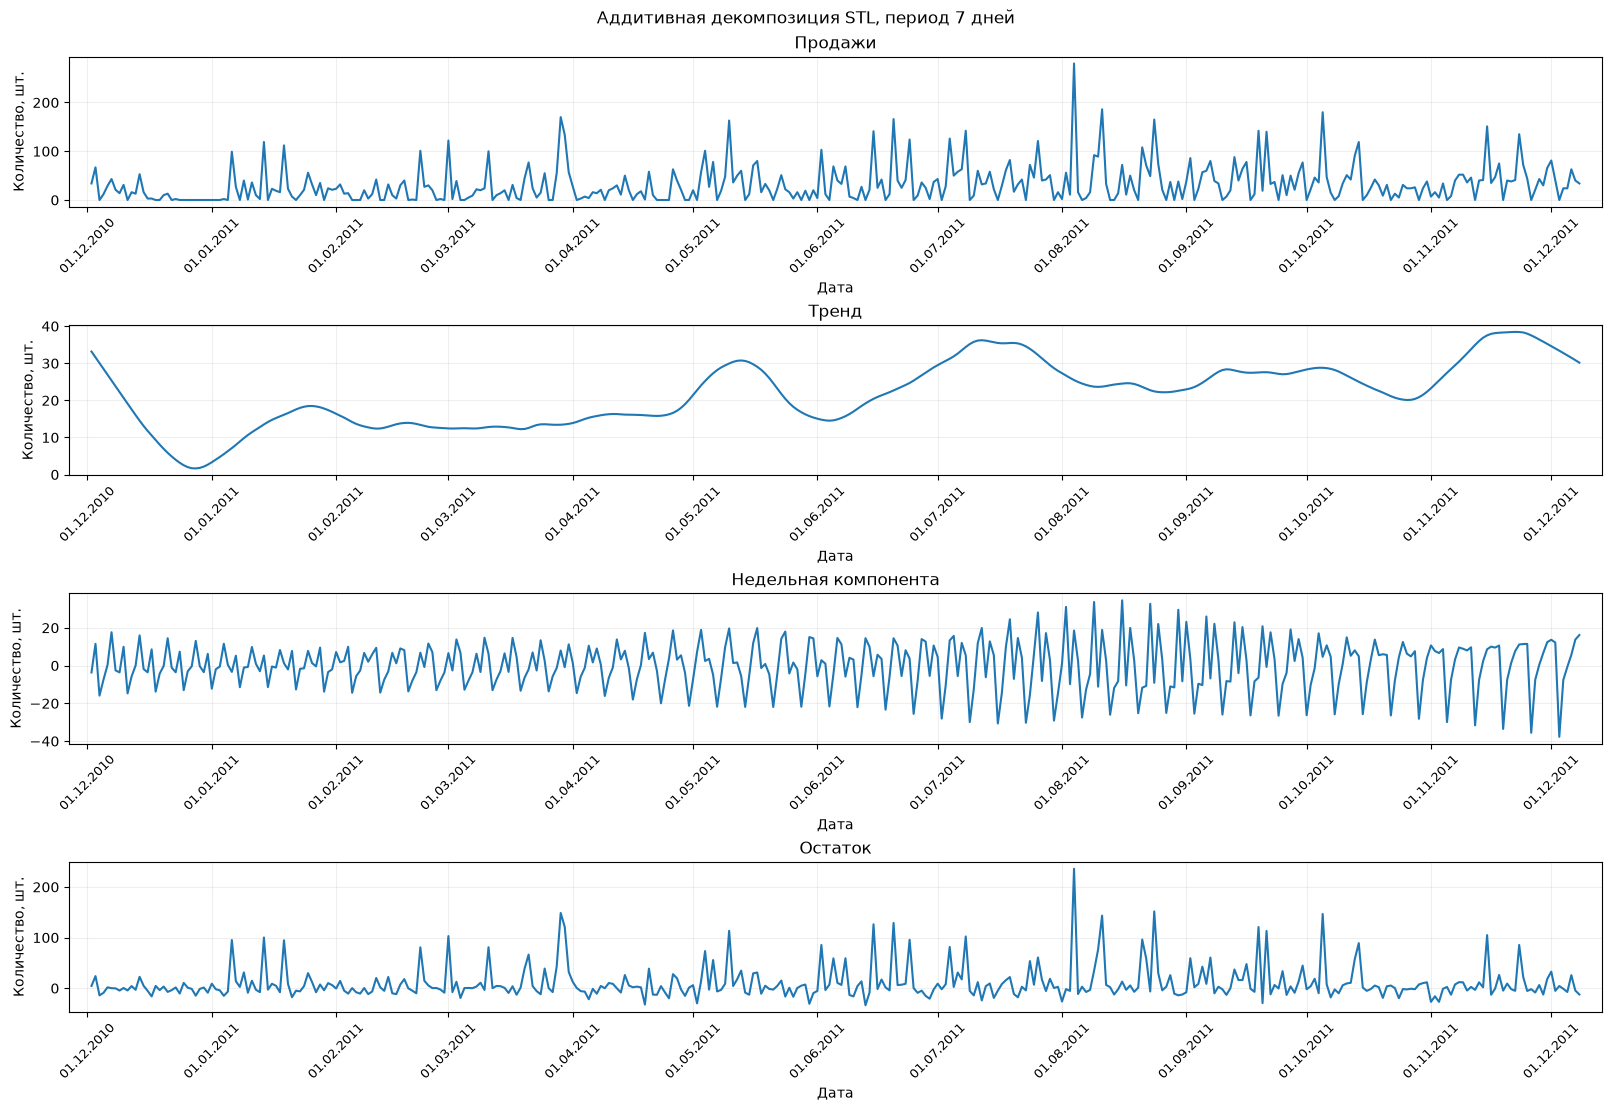

In [9]:
components = analysis.decompose()
fig, axes = plt.subplots(4, 1, figsize=(16, 11), constrained_layout=True)
for ax, column in zip(axes, components.columns):
    ax.plot(components.index, components[column])
    ax.set(title=column, ylabel='Количество, шт.')
    format_dates(ax)
fig.suptitle('Аддитивная декомпозиция STL, период 7 дней')
plt.show()

**Тренд** показывает изменение сглаженного уровня: низкие продажи на рубеже 2010–2011 годов, повышение к лету и колебания во второй половине периода. На границах оценки менее надёжны.

**Недельная компонента** отражает повторяющиеся различия между днями недели; её величина меняется во времени. **Остаток** содержит крупные положительные отклонения, согласующиеся с оптовыми заказами. Робастный STL не требует нулевого среднего остатка.

Выделяется недельный календарный рисунок, но он не объясняет крупные отдельные покупки. Годовую сезонность установить нельзя: наблюдается лишь около одного года.

## 8. Стационарность

Уровень значимости — 5%. **ADF:** нулевая гипотеза — единичный корень; **KPSS:** стационарность вокруг постоянного уровня. Используем константу в обоих тестах; лаги ADF выбираются по AIC, в KPSS берём 14 лагов, учитывая две недели зависимости. Границы табличного p-value KPSS показываем как `< 0.01` или `> 0.10`.

Изменение уровня и недельный рисунок дают основание проверить разность `y[t] − y[t−7]`. Она сравнивает продажи с тем же днём прошлой недели. Первые 7 значений неопределены и исключаются; отрицательное значение означает снижение продаж.

,Ряд,Тест,N,Статистика,p-value,Лаги
0,Исходный,ADF,372,-3.028098,0.03235,13
1,Исходный,KPSS,372,1.179481,< 0.01,14
2,Разность 7,ADF,365,-7.092810,4.366e-10,13
3,Разность 7,KPSS,365,0.027929,> 0.10,14


ACF разности на лаге 7: -0.527


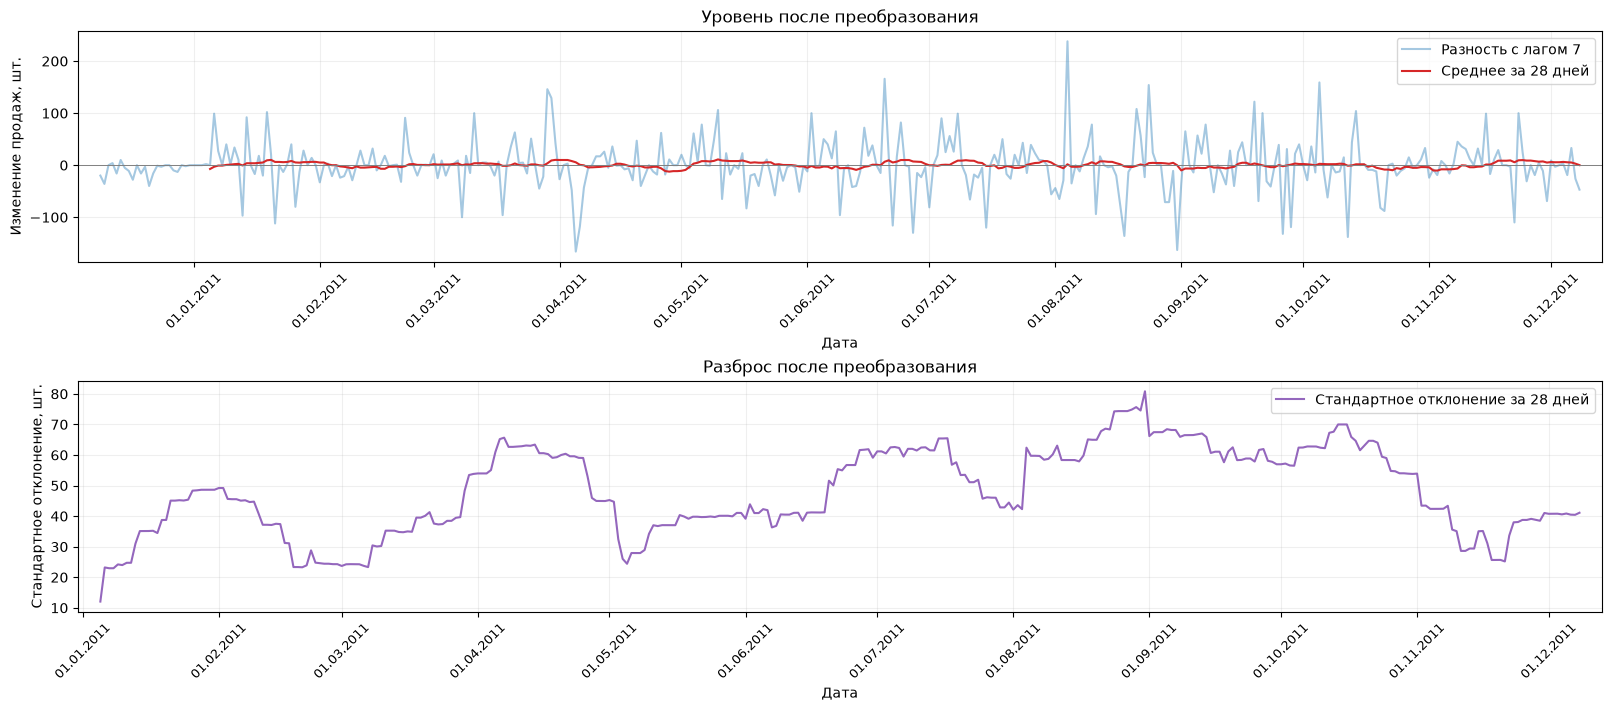

In [10]:
stationarity = analysis.stationarity()
display(stationarity)
diff_acf7 = acf(analysis.diff7, nlags=7, result_object=False)[7]
print(f'ACF разности на лаге 7: {diff_acf7:.3f}')

rolling_diff = analysis.diff7.rolling(28, min_periods=28)
fig, axes = plt.subplots(2, 1, figsize=(16, 7), constrained_layout=True)
axes[0].plot(analysis.diff7.index, analysis.diff7, alpha=0.4, label='Разность с лагом 7')
axes[0].plot(analysis.diff7.index, rolling_diff.mean(), color='tab:red', label='Среднее за 28 дней')
axes[0].axhline(0, color='grey', linewidth=0.7)
axes[0].set(title='Уровень после преобразования', ylabel='Изменение продаж, шт.')
axes[1].plot(analysis.diff7.index, rolling_diff.std(), color='tab:purple', label='Стандартное отклонение за 28 дней')
axes[1].set(title='Разброс после преобразования', ylabel='Стандартное отклонение, шт.')
for ax in axes:
    format_dates(ax)
    ax.legend()
plt.show()

На исходном ряду ADF отвергает единичный корень (`p = 0,03235`), но KPSS отвергает стационарность уровня (`p < 0,01`). Результаты противоречивы; объявлять исходный ряд стационарным нельзя.

После разности с лагом 7 остаётся 365 наблюдений. ADF отвергает единичный корень (`p ≈ 4,37 × 10⁻¹⁰`), KPSS не отвергает стационарность уровня (`p > 0,10`), скользящее среднее близко к нулю. Однако разброс остаётся неоднородным: **ковариационная стационарность не установлена**. ACF(7) = −0,527 указывает на возможное избыточное дифференцирование. Разность — проверенный вариант предобработки, а не обязательное преобразование для будущей модели.

## Итог

Построены три агрегации продаж сумки `20727`; во всех суммарно **12 240 единиц из 1 328 строк**. Календарные нули, пропуски `CustomerID` и 27 неоднозначных дубликатов рассмотрены раздельно. Ошибки в проверенном максимуме не установлены, поэтому пики сохранены.

Уровень и разброс продаж меняются, присутствует недельный календарный рисунок, частично связанный с режимом операций магазина. После разности с лагом 7 тесты согласуются со стационарностью уровня, но постоянство дисперсии не подтверждено.

Данные пригодны для дальнейшего исследования дневных и недельных продаж с учётом календаря, крупных заказов и неоднозначных дубликатов. Для надёжного вывода о годовой сезонности периода наблюдения недостаточно. Модели прогнозирования в рамках этой работы не строились.